# 31_iforest: Isolation Forest cross-check of the outlier flags

**Author:** Minh Vu · **Reviewer:** Khai Hung · **Plan:** `docs/Go.md` stage 1 step 1.5, WBS C6.1 · **Slides:** Chap 6 §5 (pp. 69–79)

**Purpose.** During preprocessing, the `cap_outlier` flag was made with **statistical rules**: a Hampel filter (far from the median of the 7 surrounding cycles) or a drop of more than 25% below the highest level of the previous 10 cycles. This notebook checks those flags with an **independent ML method**, Isolation Forest.

> ⚠ Isolation Forest is **not** one of the team's modelling algorithms (Rec.md section 2, row 12). The results here **do not change** the data or the agreed flags.

**Done when** (Go.md 1.5): there is a Hampel × iForest agreement table, a scatter plot, and an explanation of **why the recovery points after a rest (F5) should not be treated as outliers**.

Code in **`src/iforest_check.py`**:

| Class | Job |
|---|---|
| `IForestConfig` | Settings: tiers, features, seed, score threshold, colours |
| `IForestData` | Reads tiers A/B, adds ΔSOH and the position of each cycle in the battery's life |
| `IsolationForestChecker` | Fits iForest per experiment group, computes s(x, n), compares, analysis tables |
| `IForestPlots` | 2 figures |
| `IForestInsights` | Insight sentences, every number computed from the results |
| `IForestAnalysis` | Calls the classes above in order |

## How Isolation Forest works (Chap 6, pp. 75–78)

1. Each **tree** splits the data with random cuts: pick a random feature, pick a random threshold between its min and max, split in two; repeat until every point is on its own.
2. An **anomalous** point (rare, different) is isolated after **few** cuts; a normal point sits in the crowd and needs **many** cuts.
3. With 100 trees, take the mean number of cuts E[h(x)] and compute the **anomaly score**:

$$s(x, n) = 2^{-\frac{E[h(x)]}{c(n)}}$$

where c(n) is the average number of cuts needed to isolate one point among n points (normalisation). **s close to 1: very anomalous; s well below 0.5: normal.**

In sklearn, `score_samples()` returns **−s(x, n)**, so the code flips the sign; `contamination='auto'` flags a point when **s > 0.5** (the code checks this with an `assert`).

**Set-up (Go.md 1.5):**
- Data: tiers A and B, **keeping** the `cap_outlier` and `break_in` rows (those are the flags being checked).
- Features: `soh`, `d_soh` (ΔSOH against the previous cycle), `T_max_C`, `V_min`, `rest_before_h`.
- One fit **per experiment group**: the T_max_C of the 43°C group would look "anomalous" next to the 4°C group although it is normal within its own group.
- No scaling: each cut looks at one feature only, so units do not matter.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "protocol.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from iforest_check import IForestAnalysis

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
a = IForestAnalysis()            # reads the data and runs iForest (seed 42) when it is created
ck, d = a.checker, a.df
print(f"{len(d)} rows, {d.battery_id.nunique()} batteries, {d.group.nunique()} experiment groups")
print("cap_outlier:", int(d.cap_outlier.sum()), " break_in:", int(d.break_in.sum()), " long_rest:", int(d.long_rest.sum()))
d.groupby("group").agg(rows=("soh", "size"), batteries=("battery_id", "nunique"))

2020 rows, 22 batteries, 6 experiment groups
cap_outlier: 25  break_in: 9  long_rest: 130


,rows,batteries
group,,
G1,636,4
G2,112,4
G3,156,4
G4,587,3
G7,273,4
G9,256,3


## 1. Hampel × iForest agreement table

In [2]:
ck.agreement_table()

if_flag,iForest: no,iForest: yes,Total
cap_outlier,,,
Hampel: no,1786,209,1995
Hampel: yes,2,23,25
Total,1788,232,2020


In [3]:
display(Markdown(a.insights.agreement()))

**iForest agrees with almost every Hampel flag, but flags far more points.** Of the 25 rows flagged by Hampel, iForest also flags 23 (92.0%). In total iForest flags 232 rows (11.5% of the data), 9.3 times as many as Hampel. So the `cap_outlier` flags are confirmed by an independent method; the remaining question is whether the extra iForest points are wrong data.

Each row goes into exactly one category. Points flagged by iForest only are split by whether they come right after a long rest (> 1 hour):

In [4]:
ck.category_table()

,rows,% of all
category,,
both,23,1.14
Hampel only,2,0.10
iForest only: after long rest,98,4.85
iForest only: other,111,5.50
normal,1786,88.42


In [5]:
ck.by_group()

category,both,Hampel only,iForest only: after long rest,iForest only: other,normal,rows
group,,,,,,
G1,4,0,21,31,580,636
G2,3,0,9,2,98,112
G3,0,0,23,10,123,156
G4,16,0,9,27,535,587
G7,0,0,24,21,228,273
G9,0,2,12,20,222,256


## 2. Recovery points after a long rest

In [6]:
ck.long_rest_table().round(4)

,rows,median ΔSOH,% with ΔSOH > 0,% flagged by iForest,% flagged by Hampel,"median s(x, n)"
rest,,,,,,
rest > 1 h,130,0.0107,79.2308,84.6154,9.2308,0.5975
rest <= 1 h,1890,-0.0031,24.8677,6.4550,0.6878,0.4148


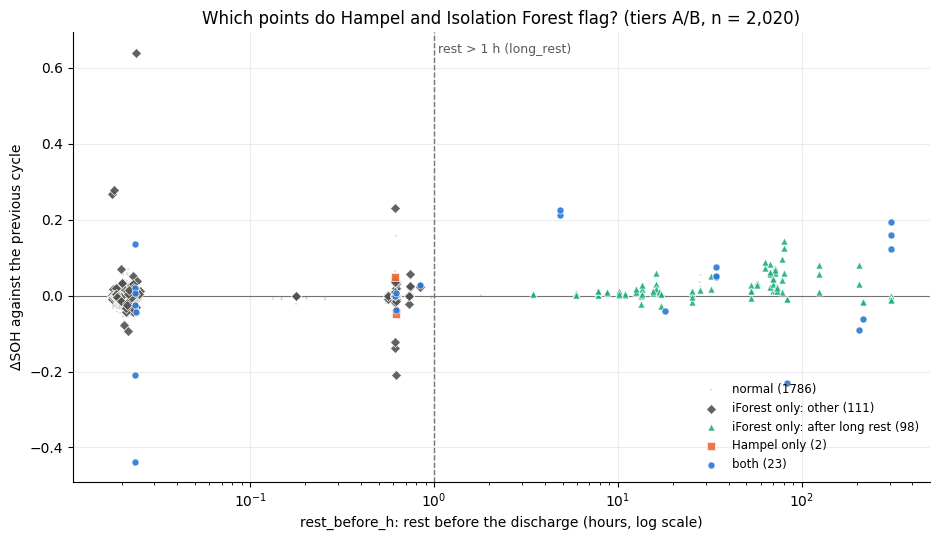

**Almost half of the extra iForest points are capacity recoveries after a rest.** After a rest of more than 1 hour, the median ΔSOH is +0.0107 and 79.2% of cycles show a higher SOH, against a median of -0.0031 after a short rest. iForest flags 84.6% of the long-rest cycles, Hampel only 9.2%. Of the 209 points flagged by iForest only, 98 (46.9%) come right after a long rest.

In [7]:
fig = a.plots.rest_scatter()
plt.show()
display(Markdown(a.insights.recovery()))

**How to read the figure:** the x axis is the rest time (log scale), the y axis is ΔSOH. To the right of the dashed line (rest > 1 hour), most points sit **above** zero (SOH goes up) and most are green: flagged by iForest, not by Hampel. The two clusters of short rests on the left are the two standard rest lengths of the test procedure.

### Examples on single batteries

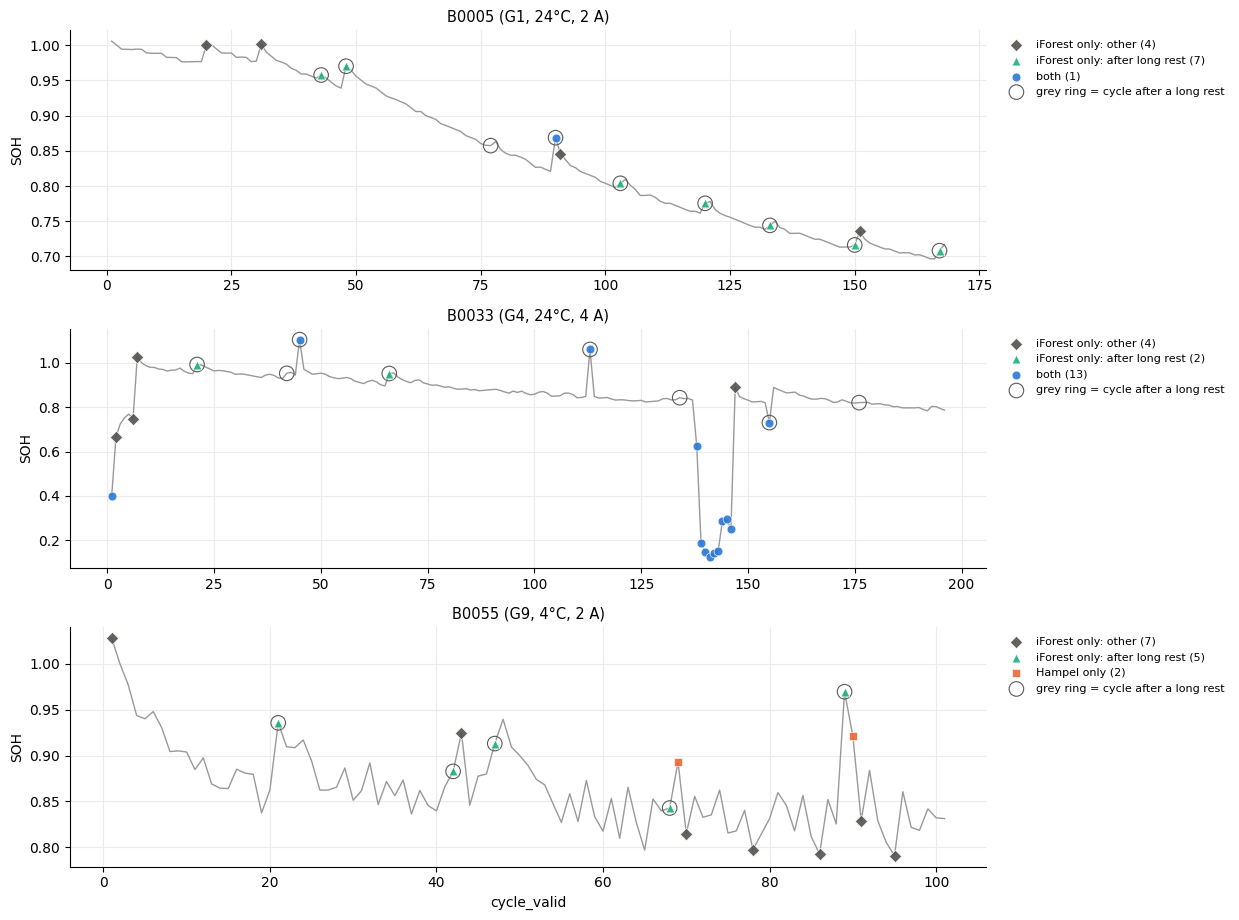

In [8]:
fig = a.plots.example_curves()
plt.show()

- **B0005 (G1):** almost every upward SOH "spike" (green triangle) comes right after a long rest (grey ring), and SOH then returns to its downward trend. This is capacity recovery, not an error.
- **B0033 (G4):** the capacity drop around cycles 139–148 (a *collective anomaly*, F10) and the start-up cycles at the beginning of the series are flagged by **both** methods.
- **B0055 (G9):** SOH varies strongly along the whole series; this is where the points flagged by Hampel only are.

## 3. Why the recovery points should not be treated as outliers

In [9]:
display(Markdown(a.insights.why_not_outlier()))

**Why the recovery points should NOT be treated as outliers.** iForest flags them because they are rare and different: SOH jumps up against the downward trend, together with an unusually long rest. But this is a real electrochemical effect (capacity recovery, F5 in Introduction_of_dataset), usually explained as follows: while the battery rests, the lithium-ion concentration inside the electrodes has time to even out, so the capacity rises for a while and then falls back to the trend after a few cycles (see the example figure). It happens exactly when there is a cause (a long rest), it repeats in 17 batteries from 5 experiment groups, and it has a fixed direction (SOH goes up), unlike measurement errors, which are random. Deleting these points would lose information: rest time is one of the most important non-history features of the SVR model. So the team keeps these points and uses the `long_rest` flag as an explanatory variable. Lesson: "statistically unusual" does not mean "wrong data"; a decision to remove points must rest on an understanding of the phenomenon.

## 4. Points flagged by iForest only for other reasons

In [10]:
ck.if_only_reasons()

,rows,% of iForest-only points
after a long rest (long_rest),98,46.9
other,56,26.8
first or last 10% of life,55,26.3


In [11]:
display(Markdown(a.insights.other_if_only()))

**Points flagged by iForest only, not after a long rest (111 points).** 55 of them lie in the first or last 10% of the battery's life: at both ends of a series, SOH or ΔSOH tends to sit at the edge of the group's range and is isolated with few cuts, although this may just be normal behaviour (start-up or end of life). For the other 56 points, the feature furthest from its group is: d_soh (36), rest_before_h (9), V_min (5), T_max_C (3), soh (3); most are moderate ΔSOH jumps that stay below the Hampel threshold. This follows from contamination='auto' (the s > 0.5 threshold is fairly loose), not from wrong data.

## 5. Fair comparison: same flagging rate

`contamination='auto'` lets iForest flag far more points than Hampel. For a fair comparison, iForest is forced to flag **exactly Hampel's share** of rows in each group, and the overlap is counted.

In [12]:
ck.same_rate_comparison().round(4)

,flag rate,iForest flags,Hampel flags,both,iForest only,of which after a long rest
0,0.0124,28,25,12,16,16


In [13]:
display(Markdown(a.insights.same_rate()))
display(Markdown(a.insights.hampel_only()))

**Comparison at the same flagging rate.** If iForest may only flag 1.24% of the data like Hampel (28 rows), the two methods share only 12 rows; 16 / 16 of the remaining points come after a long rest. So the points iForest finds "most unusual" are mainly recoveries, not only the deviations from the trend that Hampel targets. The two methods answer different questions: Hampel looks for points that leave the trend of their own series; iForest looks for rare points in a space of several features.

**2 points flagged by Hampel only:** B0055 cycle 69 (ΔSOH 0.050, s = 0.48), B0055 cycle 90 (ΔSOH -0.049, s = 0.48). Their score s is close to the 0.5 threshold: they leave the trend of their own battery (what Hampel looks at), but are not rare enough within the whole group G9, where SOH already varies a lot.

## 6. Stability across seeds

iForest uses random cuts, so the result depends on the seed. Rerun with 5 other seeds:

In [14]:
ck.seed_stability().round(3)

,points flagged,Jaccard with seed 42,Hampel flags caught (of 25)
seed,,,
42,232,1.000,23
0,245,0.793,25
1,247,0.835,24
2,258,0.835,24
3,215,0.767,24
4,258,0.822,24


In [15]:
display(Markdown(a.insights.stability()))

**Stability.** Rerun with 5 other seeds, the number of flagged points ranges from 215 to 258, and the Jaccard overlap with seed 42 from 0.77 to 0.84. Points close to the 0.5 threshold can switch between runs, but the conclusion about the recovery points does not change.

## 7. Conclusion

1. The `cap_outlier` flags are **confirmed** by an independent ML method (iForest catches almost all of them).
2. iForest flags many extra points; the largest group of them are **capacity recoveries after long rests**: a real effect with a clear cause, so they are **kept**, and the `long_rest` flag is used as an explanatory variable, as already agreed.
3. **No change is proposed** to the cleaning rules or the agreed flags.

Figures are saved in `reports/figures/iforest_rest_scatter.png` and `reports/figures/iforest_examples.png`.